In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import gc

from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)


from pathlib import Path

PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta data/processed."
    )

DATA_DIR = PROJECT_DIR / "data" / "processed"

train = pd.read_csv(DATA_DIR / "ghi_multisitio_entrenamiento.csv")
validacion = pd.read_csv(DATA_DIR / "ghi_multisitio_validacion.csv")
test = pd.read_csv(DATA_DIR / "ghi_multisitio_prueba.csv")


for df in [train, validacion, test]:
    df["fecha_hora"] = pd.to_datetime(df["fecha_hora"])

print("Train:", train.shape)
print("Validación:", validacion.shape)
print("Test:", test.shape)

Train: (262944, 16)
Validación: (52560, 16)
Test: (25992, 16)


In [ ]:
features = [
    "ghi",
    "ghi_lag_1",
    "ghi_lag_24",
    "temp",
    "vel",
    "cloud",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos",
    "colchane",
    "pica"
]

target = "ghi_t1"
columnas_necesarias = features + [target]

for df in [train, validacion, test]:
    df.dropna(subset=columnas_necesarias, inplace=True)
    df.sort_values(["comuna", "fecha_hora"], inplace=True)
    df.reset_index(drop=True, inplace=True)

In [ ]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

scaler_X.fit(train[features])
scaler_y.fit(train[[target]])

StandardScaler()

In [ ]:
ventana = 24

def crear_secuencias(df_actual, df_historial=None):

    X_total = []
    y_total = []
    metadata_total = []

    for comuna in sorted(df_actual["comuna"].unique()):

        actual = (
            df_actual[df_actual["comuna"] == comuna]
            .sort_values("fecha_hora")
            .reset_index(drop=True)
        )

        if df_historial is None:

            combinado = actual.copy()

            X_escalado = scaler_X.transform(
                combinado[features]
            ).astype(np.float32)

            ventanas = sliding_window_view(
                X_escalado,
                window_shape=ventana,
                axis=0
            ).transpose(0, 2, 1)

            y = actual[target].to_numpy(
                dtype=np.float32
            )[ventana - 1:]

            metadata = actual[
                ["fecha_hora", "comuna"]
            ].iloc[ventana - 1:].copy()

        else:

            historial = (
                df_historial[
                    df_historial["comuna"] == comuna
                ]
                .sort_values("fecha_hora")
                .tail(ventana - 1)
            )

            combinado = pd.concat(
                [historial, actual],
                ignore_index=True
            )

            X_escalado = scaler_X.transform(
                combinado[features]
            ).astype(np.float32)

            ventanas = sliding_window_view(
                X_escalado,
                window_shape=ventana,
                axis=0
            ).transpose(0, 2, 1)

            y = actual[target].to_numpy(
                dtype=np.float32
            )

            metadata = actual[
                ["fecha_hora", "comuna"]
            ].copy()

        X_total.append(ventanas)
        y_total.append(y)
        metadata_total.append(metadata)

    return (
        np.concatenate(X_total),
        np.concatenate(y_total),
        pd.concat(metadata_total, ignore_index=True)
    )

In [ ]:
X_train_seq, y_train_seq, meta_train = crear_secuencias(
    train
)

X_valid_seq, y_valid_seq, meta_valid = crear_secuencias(
    validacion,
    df_historial=train
)

X_test_seq, y_test_seq, meta_test = crear_secuencias(
    test,
    df_historial=validacion
)

y_train_scaled = scaler_y.transform(
    y_train_seq.reshape(-1, 1)
).ravel()

y_valid_scaled = scaler_y.transform(
    y_valid_seq.reshape(-1, 1)
).ravel()

print("Train:", X_train_seq.shape)
print("Validación:", X_valid_seq.shape)
print("Test:", X_test_seq.shape)

Train: (262875, 24, 12)
Validación: (52560, 24, 12)
Test: (25989, 24, 12)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
configuraciones_lstm = {
    "LSTM 1": 32,
    "LSTM 2": 64
}
#LSTM 1: 32 unidades.
#LSTM 2: 64 unidades.

In [ ]:
#crear y validar modelos
resultados_validacion_lstm = []

for nombre, unidades in configuraciones_lstm.items():

    print(f"\nEntrenando {nombre}")

    tf.keras.backend.clear_session()

    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(
            shape=(ventana, len(features))
        ),
        tf.keras.layers.LSTM(unidades),
        tf.keras.layers.Dense(1)
    ])

    modelo.compile(
        optimizer="adam",
        loss="mse"
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    )

    historia = modelo.fit(
        X_train_seq,
        y_train_scaled,
        validation_data=(
            X_valid_seq,
            y_valid_scaled
        ),
        epochs=50,
        batch_size=256,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=0
    )

    pred_scaled = modelo.predict(
        X_valid_seq,
        verbose=0
    )

    pred_valid = scaler_y.inverse_transform(
        pred_scaled
    ).ravel()

    pred_valid = np.clip(pred_valid, 0, None)

    resultados_validacion_lstm.append({
        "Configuración": nombre,
        "Ventana": ventana,
        "Unidades LSTM": unidades,
        "Épocas ejecutadas": len(historia.history["loss"]),
        "MAE": mean_absolute_error(
            y_valid_seq,
            pred_valid
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_valid_seq,
                pred_valid
            )
        ),
        "R2": r2_score(
            y_valid_seq,
            pred_valid
        )
    })

    del modelo
    gc.collect()


Entrenando LSTM 1

Entrenando LSTM 2


In [ ]:
#mostrar resultados
tabla_validacion_lstm = pd.DataFrame(
    resultados_validacion_lstm
).sort_values("MAE")

display(tabla_validacion_lstm)

,Configuración,Ventana,Unidades LSTM,Épocas ejecutadas,MAE,RMSE,R2
1,LSTM 2,24,64,23,24.750408,66.583183,0.970794
0,LSTM 1,24,32,14,26.836439,68.438477,0.969143


In [ ]:
#entrenamiento final
train_final = pd.concat(
    [train, validacion],
    ignore_index=True
)

train_final = (
    train_final
    .dropna(subset=columnas_necesarias)
    .sort_values(["comuna", "fecha_hora"])
    .reset_index(drop=True)
)

test_final = (
    test
    .dropna(subset=columnas_necesarias)
    .sort_values(["comuna", "fecha_hora"])
    .reset_index(drop=True)
)

print("Entrenamiento final:", train_final.shape)
print("Test:", test_final.shape)

Entrenamiento final: (315504, 16)
Test: (25989, 16)


In [ ]:
scaler_X_final = StandardScaler()
scaler_y_final = StandardScaler()

scaler_X_final.fit(train_final[features])
scaler_y_final.fit(train_final[[target]])

StandardScaler()

In [ ]:
ventana = 24

def crear_secuencias_final(df_actual, df_historial=None):

    X_total = []
    y_total = []
    meta_total = []

    for comuna in sorted(df_actual["comuna"].unique()):

        actual = (
            df_actual[df_actual["comuna"] == comuna]
            .sort_values("fecha_hora")
            .reset_index(drop=True)
        )

        if df_historial is None:

            combinado = actual.copy()
            inicio_objetivo = ventana - 1

        else:

            historial = (
                df_historial[df_historial["comuna"] == comuna]
                .sort_values("fecha_hora")
                .tail(ventana - 1)
            )

            combinado = pd.concat(
                [historial, actual],
                ignore_index=True
            )

            inicio_objetivo = 0

        X_escalado = scaler_X_final.transform(
            combinado[features]
        ).astype(np.float32)

        ventanas = sliding_window_view(
            X_escalado,
            window_shape=ventana,
            axis=0
        ).transpose(0, 2, 1)

        y = actual[target].to_numpy(
            dtype=np.float32
        )[inicio_objetivo:]

        metadata = actual[
            ["fecha_hora", "comuna"]
        ].iloc[inicio_objetivo:].copy()

        X_total.append(ventanas)
        y_total.append(y)
        meta_total.append(metadata)

    return (
        np.concatenate(X_total),
        np.concatenate(y_total),
        pd.concat(meta_total, ignore_index=True)
    )

In [ ]:
#crear entrenamiento y prueba
X_train_final_seq, y_train_final_seq, _ = (
    crear_secuencias_final(train_final)
)

X_test_final_seq, y_test_final_seq, meta_test_final = (
    crear_secuencias_final(
        test_final,
        df_historial=train_final
    )
)

y_train_final_scaled = scaler_y_final.transform(
    y_train_final_seq.reshape(-1, 1)
).ravel()

print("Train:", X_train_final_seq.shape)
print("Test:", X_test_final_seq.shape)

Train: (315435, 24, 12)
Test: (25989, 24, 12)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
#entrenar modelo definitivo
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

modelo_lstm_final = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(ventana, len(features))
    ),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(1)
])

modelo_lstm_final.compile(
    optimizer="adam",
    loss="mse"
)

modelo_lstm_final.fit(
    X_train_final_seq,
    y_train_final_scaled,
    epochs=23,
    batch_size=256,
    shuffle=False,
    verbose=0
)

print("Modelo LSTM final entrenado.")

Modelo LSTM final entrenado.


In [ ]:
#predicción y métricas globales
pred_test_scaled = modelo_lstm_final.predict(
    X_test_final_seq,
    verbose=0
)

pred_test_lstm_original = scaler_y_final.inverse_transform(
    pred_test_scaled
).ravel()

pred_test_lstm = np.clip(
    pred_test_lstm_original,
    0,
    None
)

mae_lstm = mean_absolute_error(
    y_test_final_seq,
    pred_test_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        y_test_final_seq,
        pred_test_lstm
    )
)

r2_lstm = r2_score(
    y_test_final_seq,
    pred_test_lstm
)

print("LSTM FINAL")
print(f"MAE:  {mae_lstm:.4f} W/m²")
print(f"RMSE: {rmse_lstm:.4f} W/m²")
print(f"R²:   {r2_lstm:.4f}")

LSTM FINAL
MAE:  16.2447 W/m²
RMSE: 54.6725 W/m²
R²:   0.9808


In [ ]:
#tabla de resultados
resultados_test_lstm = meta_test_final.copy()

resultados_test_lstm["fecha_objetivo"] = (
    resultados_test_lstm["fecha_hora"]
    + pd.Timedelta(hours=1)
)

resultados_test_lstm["ghi_real"] = y_test_final_seq
resultados_test_lstm["ghi_pronosticado"] = pred_test_lstm

resultados_test_lstm["residuo"] = (
    resultados_test_lstm["ghi_real"]
    - resultados_test_lstm["ghi_pronosticado"]
)

display(resultados_test_lstm.head())

,fecha_hora,comuna,fecha_objetivo,ghi_real,ghi_pronosticado,residuo
0,2016-01-01 00:00:00,colchane,2016-01-01 01:00:00,0.0,0.000000,0.000000
1,2016-01-01 01:00:00,colchane,2016-01-01 02:00:00,0.0,0.000000,0.000000
2,2016-01-01 02:00:00,colchane,2016-01-01 03:00:00,0.0,0.000000,0.000000
3,2016-01-01 03:00:00,colchane,2016-01-01 04:00:00,0.0,0.000000,0.000000
4,2016-01-01 04:00:00,colchane,2016-01-01 05:00:00,0.0,1.131075,-1.131075


In [ ]:
#métrica por localidad
metricas_lstm_localidad = []

for comuna, grupo in resultados_test_lstm.groupby("comuna"):

    metricas_lstm_localidad.append({
        "Localidad": comuna,
        "MAE": mean_absolute_error(
            grupo["ghi_real"],
            grupo["ghi_pronosticado"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                grupo["ghi_real"],
                grupo["ghi_pronosticado"]
            )
        ),
        "R2": r2_score(
            grupo["ghi_real"],
            grupo["ghi_pronosticado"]
        )
    })

metricas_lstm_localidad = pd.DataFrame(
    metricas_lstm_localidad
)

display(metricas_lstm_localidad)

,Localidad,MAE,RMSE,R2
0,colchane,23.084740,72.403623,0.968255
1,pica,11.579453,42.157027,0.988328
2,pozo_almonte,14.069870,44.133454,0.986950


In [ ]:
#residuos
print(
    "Media de residuos:",
    resultados_test_lstm["residuo"].mean()
)

print(
    "Desviación estándar:",
    resultados_test_lstm["residuo"].std()
)

print(
    "Predicciones negativas originales:",
    np.sum(pred_test_lstm_original < 0)
)

Media de residuos: -4.120187
Desviación estándar: 54.51502227783203
Predicciones negativas originales: 8714


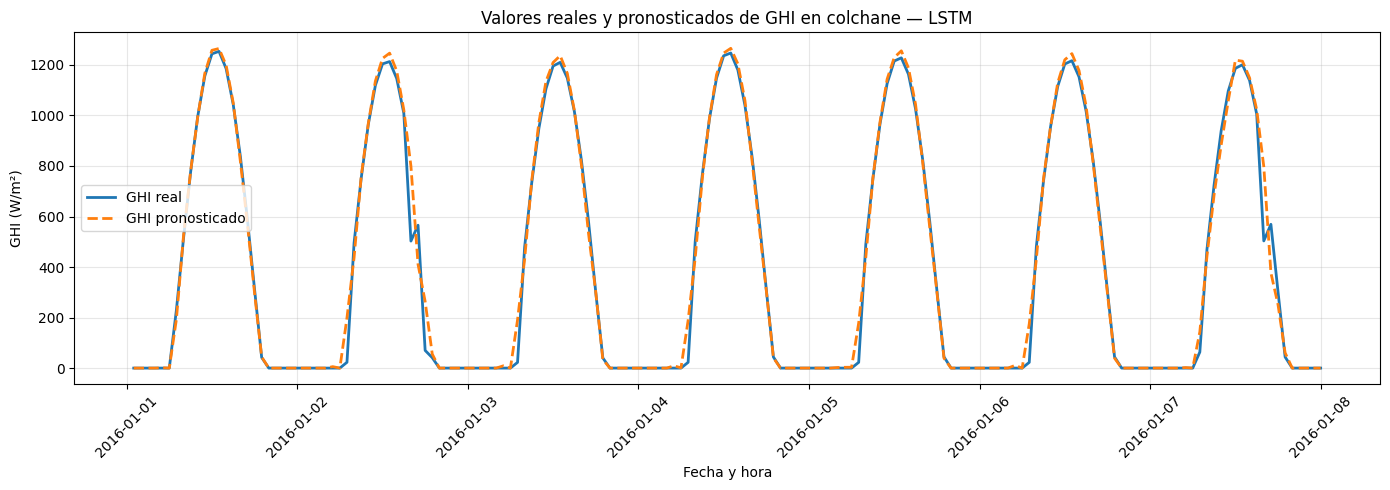

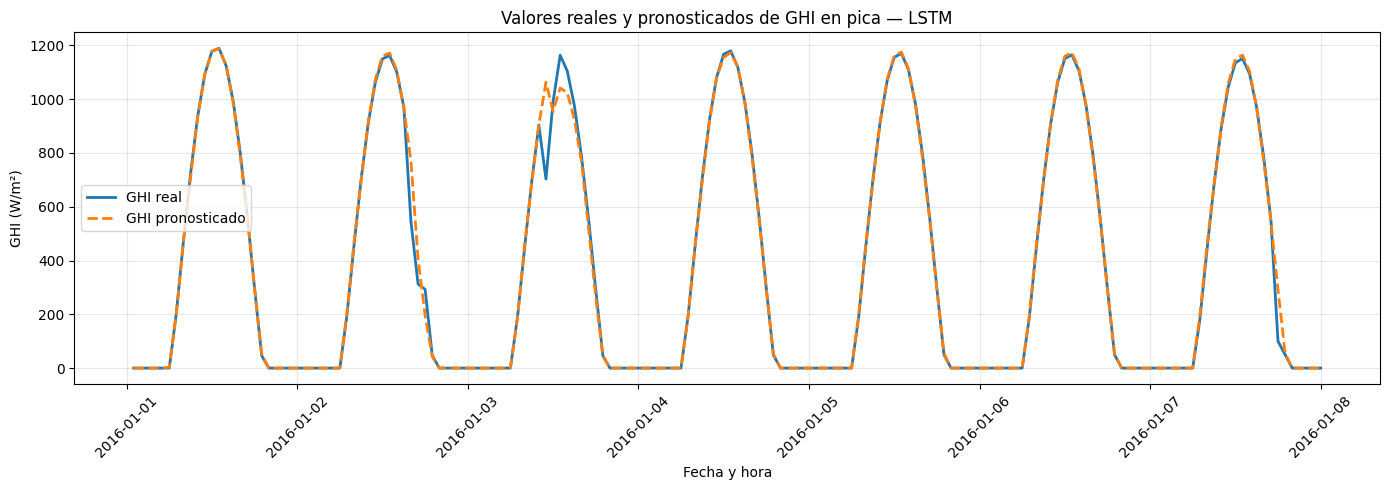

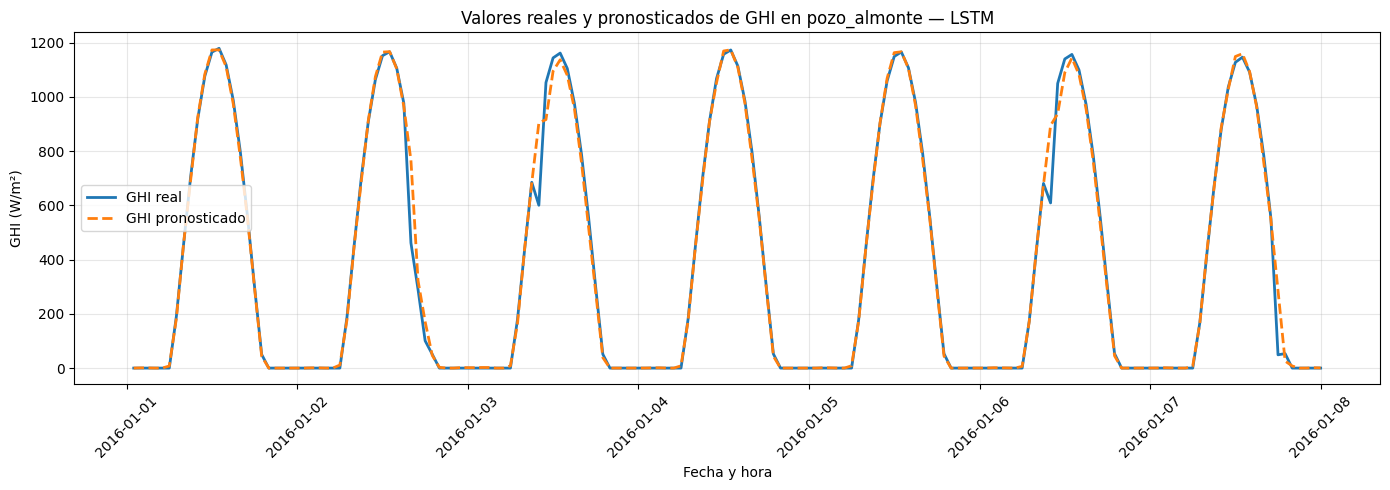

In [ ]:
#gráficos
import matplotlib.pyplot as plt


FIGURES_DIR = PROJECT_DIR / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


for comuna in resultados_test_lstm["comuna"].unique():

    muestra = (
        resultados_test_lstm[
            resultados_test_lstm["comuna"] == comuna
        ]
        .sort_values("fecha_objetivo")
        .head(24 * 7)
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        muestra["fecha_objetivo"],
        muestra["ghi_real"],
        label="GHI real",
        linewidth=2
    )

    plt.plot(
        muestra["fecha_objetivo"],
        muestra["ghi_pronosticado"],
        label="GHI pronosticado",
        linestyle="--",
        linewidth=2
    )

    plt.title(
        f"Valores reales y pronosticados de GHI en {comuna} — LSTM"
    )

    plt.xlabel("Fecha y hora")
    plt.ylabel("GHI (W/m²)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()


    plt.savefig(
        FIGURES_DIR / f"lstm_real_vs_pronosticado_{comuna}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

In [ ]:
#guardar modelo
import joblib
import json

ruta_modelos = PROJECT_DIR / "models" / "lstm"
ruta_modelos.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


In [ ]:
modelo_lstm_final.save(
    ruta_modelos / "modelo_lstm_final.keras"
)

joblib.dump(
    scaler_X_final,
    ruta_modelos / "scaler_X_lstm.joblib"
)

joblib.dump(
    scaler_y_final,
    ruta_modelos / "scaler_y_lstm.joblib"
)

print("Modelo LSTM y escaladores guardados correctamente.")


In [ ]:
configuracion_lstm = {
    "ventana": 24,
    "features": features,
    "target": target,
    "unidades_lstm": 64
}

with open(
    f"{ruta_modelos}/configuracion_lstm.json",
    "w"
) as archivo:
    json.dump(configuracion_lstm, archivo, indent=4)